# Procurement Spend Cube & Auto-Classification
**Client:** Indonesian upstream oil & gas operator (name withheld) · **Scope:** 5 years of PO lines (2021-2025), ~855k rows, ~USD 6.2B spend

**Problem.** Category managers could not answer basic questions — *how much do we spend on valves? with how many vendors?* — because
only ~48% of PO lines carried a category, about 1 in 10 of those labels was wrong, vendor records were duplicated, and item descriptions
were free text in mixed English/Bahasa Indonesia.

**What this notebook does**
1. Profiles and cleans the raw SAP PO-line extract
2. Normalises the vendor master (duplicate records under one tax ID)
3. Trains a text classifier that assigns every PO line to a 3-level category taxonomy (UNSPSC-aligned)
4. Builds the spend cube (category × vendor × site × year) and the analyses category managers asked for
5. Exports the tables behind the dashboard (`docs/index.html`)

> Data note: the original client data is confidential. This repository runs on a synthetic replica generated to match the
> structure, volumes and data-quality issues of the original extract (`src/generate_data.py`).

## 1. Load & profile

In [1]:
import re, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30, "display.width", 160, "display.float_format", "{:,.2f}".format)

RAW, OUT, FIG = Path("../data/raw"), Path("../data/processed"), Path("../outputs/figures")
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.facecolor": "#f6f4ef", "axes.facecolor": "#f6f4ef", "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "axes.titleweight": "bold"})
ACC = "#1f5f5b"

po = pd.read_csv(RAW / "po_lines_2021_2025.csv", dtype={"po_number": str, "material_code": str})
vendors = pd.read_csv(RAW / "vendor_master.csv")
taxo = pd.read_csv(RAW / "category_taxonomy.csv")
qa = pd.read_csv(RAW / "qa_validated_sample.csv")
print(f"PO lines: {len(po):,} | POs: {po.po_number.nunique():,} | vendors in master: {len(vendors):,} | categories (L3): {len(taxo)}")
po.head()

PO lines: 855,300 | POs: 322,110 | vendors in master: 1,383 | categories (L3): 50


,line_id,po_number,po_line,po_date,delivery_date,plant,cost_center,requester_dept,buyer_id,vendor_id,contract_no,po_type,material_code,item_description,quantity,uom,unit_price,currency,fx_rate_idr_usd,net_value,net_value_usd,gl_account,category_manual
0,1,4500100000,10,2021-01-01,2021-01-21,ONS-SKT,ONSSKT-IT,IT,BYR-09,V101214,CTR-2021-0385,Service,NaN,ERP support & maintenance 2021,34.00,USER,"1,121.21",USD,"14,229.00","38,121.14","38,121.14",5301000 - G&A Services,NaN
1,2,4500100001,10,2021-01-01,2021-04-19,ONS-SKT,ONSSKT-PRO,Production Ops,BYR-22,V100640,NaN,Material,20004857,V-BELT B-75 ex PR10022690,3.00,EA,"561,300.00",IDR,"14,229.00","1,683,900.00",118.34,5101100 - Materials & Supplies,NaN
2,3,4500100001,20,2021-01-01,2021-01-22,ONS-SKT,ONSSKT-PRO,Production Ops,BYR-22,V100640,NaN,Material,20000049,baut mur m20 x 150 ss304,2.00,SET,"2,523,750.00",IDR,"14,229.00","5,047,500.00",354.73,5101200 - Spare Parts,NaN
3,4,4500100001,30,2021-01-01,2021-03-23,ONS-SKT,ONSSKT-PRO,Production Ops,BYR-22,V100640,NaN,Material,NaN,BEARING 22220 2RS C3,3.00,SET,"1,531,000.00",IDR,"14,229.00","4,593,000.00",322.79,1401000 - Inventory (Stock),NaN
4,5,4500100001,40,2021-01-01,2021-03-15,ONS-SKT,ONSSKT-PRO,Production Ops,BYR-22,V100640,NaN,Material,NaN,BEARING 6205 2RS C3,2.00,EA,"609,600.00",IDR,"14,229.00","1,219,200.00",85.68,5101200 - Spare Parts,NaN


In [2]:
profile = pd.DataFrame({"dtype": po.dtypes.astype(str), "null_%": po.isna().mean().mul(100).round(2), "unique": po.nunique()})
profile

,dtype,null_%,unique
line_id,int64,0.00,855300
po_number,str,0.00,322110
po_line,int64,0.00,36
po_date,str,0.00,1304
delivery_date,str,0.00,1944
plant,str,0.20,10
cost_center,str,0.00,53
requester_dept,str,0.00,14
buyer_id,str,0.00,26
vendor_id,str,0.00,1383


In [3]:
print("Exact duplicate lines   :", po.drop(columns="line_id").duplicated().sum())
print("Plant codes             :", sorted(po.plant.dropna().unique()))
print("Currency codes          :", po.currency.value_counts().to_dict())
print("Zero-value lines        :", (po.net_value_usd == 0).sum())
valid = set(taxo.category_l3)
cm = po.category_manual
print(f"Lines with a category   : {cm.notna().mean():.1%}  (of which not in taxonomy: {(~cm.dropna().isin(valid)).sum():,})")

Exact duplicate lines   : 2983
Plant codes             : ['HO-JKT', 'OFF-MRB', 'ONS-SKT', 'SB-BPN', 'SB-PLM', 'ho-jkt', 'off-mrb', 'ons-skt', 'sb-bpn', 'sb-plm']
Currency codes          : {'IDR': 467192, 'USD': 383449, 'Rp': 4659}
Zero-value lines        : 1319
Lines with a category   : 48.4%  (of which not in taxonomy: 12,584)


## 2. Cleaning

In [4]:
df = po.copy()
n0 = len(df)
df = df[~df.drop(columns="line_id").duplicated()]                 # exact duplicates from the extract
df["plant"] = df["plant"].str.upper()
# plant missing -> recover from cost centre prefix
cc_map = {"HOJKT": "HO-JKT", "ONSSKT": "ONS-SKT", "OFFMRB": "OFF-MRB", "SBBPN": "SB-BPN", "SBPLM": "SB-PLM"}
df["plant"] = df["plant"].fillna(df["cost_center"].str.split("-").str[0].map(cc_map))
df["currency"] = df["currency"].replace({"Rp": "IDR"})
zero = df["net_value_usd"].eq(0)
df = df[~zero]
df["po_date"] = pd.to_datetime(df["po_date"])
df["year"] = df.po_date.dt.year
# reconcile USD value with currency and monthly FX
chk = np.where(df.currency.eq("USD"), df.net_value, df.net_value / df.fx_rate_idr_usd)
print(f"Removed duplicates: {n0 - len(df) - zero.sum():,} | removed zero-value lines: {zero.sum():,} | rows now: {len(df):,}")
print("Max USD reconciliation gap:", round(np.abs(chk - df.net_value_usd).max(), 2))
print("Plant nulls after fix:", df.plant.isna().sum())

Removed duplicates: 2,983 | removed zero-value lines: 1,312 | rows now: 851,005
Max USD reconciliation gap: 0.01
Plant nulls after fix: 0


## 3. Vendor normalisation
Same legal entity, several vendor IDs (e.g. `PT Sinar Baja Teknik` vs `SINAR BAJA TEKNIK, PT`). Tax ID is the anchor; the earliest record becomes the golden record.

In [5]:
def clean_name(s):
    s = s.upper()
    s = re.sub(r"\b(PT|P\.T|CV)\b\.?", " ", s)
    s = re.sub(r"\b(PTE\.? LTD\.?|SDN\.? BHD\.?|INC\.?|LIMITED|LTD\.?|CO\.?,? LTD\.?|GMBH|FZE)\b", " ", s)
    s = re.sub(r"\(BRANCH\)", " ", s)
    return " ".join(re.sub(r"[^A-Z0-9 ]", " ", s).split())

vendors["name_key"] = vendors.vendor_name.map(clean_name)
golden = (vendors.sort_values("created_date").groupby("tax_id")
          .agg(master_vendor_id=("vendor_id", "first"), master_vendor_name=("vendor_name", "first"), n_records=("vendor_id", "size")))
vmap = vendors.merge(golden, on="tax_id")
dup = vmap[vmap.n_records > 1]
print(f"Vendor IDs: {len(vendors):,} -> unique legal entities: {len(golden):,} ({len(dup) - dup.tax_id.nunique():,} duplicate records)")
print("Name-key check: duplicates whose cleaned names also match:", (dup.groupby('tax_id').name_key.nunique() == 1).mean().round(3))
dup.sort_values("tax_id")[["tax_id", "vendor_id", "vendor_name", "created_date"]].head(8)

Vendor IDs: 1,383 -> unique legal entities: 1,311 (72 duplicate records)
Name-key check: duplicates whose cleaned names also match: 0.903


,tax_id,vendor_id,vendor_name,created_date
343,021281626659982,V100344,CV Baja Industri,2008-03-25
1353,021281626659982,V101354,"Baja Industri, CV",2014-06-05
427,021727939425460,V100428,PT Garuda Eka Teknik,2010-03-03
1322,021727939425460,V101323,PT. Garuda Eka Teknik,2016-05-19
278,045842047739476,V100279,PT Graha Tirta Pompa Indonesia,2015-09-16
1360,045842047739476,V101361,P.T GRAHA TIRTA POMPA INDONESIA,2020-12-31
1138,057265437911251,V101139,PT Nusa Karya Medika,2014-10-18
1373,057265437911251,V101374,P.T NUSA KARYA MEDIKA,2020-02-14


In [6]:
df = df.merge(vmap[["vendor_id", "master_vendor_id", "master_vendor_name", "country", "vendor_type"]], on="vendor_id", how="left")
df["vendor_origin"] = np.where(df.country.eq("Indonesia"), "Local (Indonesia)", "Foreign")
spend_on_dups = df[df.vendor_id != df.master_vendor_id].net_value_usd.sum()
print(f"Spend booked on duplicate vendor IDs: USD {spend_on_dups/1e6:,.1f}M — invisible in vendor-level reports before the merge")

Spend booked on duplicate vendor IDs: USD 97.3M — invisible in vendor-level reports before the merge


## 4. Auto-classification of PO lines
Training labels = buyer-assigned categories that exist in the taxonomy (noisy). Evaluation uses the **2,000-line sample validated by category managers**, which the model never sees.

In [7]:
def norm_desc(s):
    s = str(s).lower()
    s = re.sub(r"\bex pr\d+", " ", s)
    s = s.replace("urgent -", " ")
    s = re.sub(r"(\d+)\s*(\")", r"\1in", s)
    s = re.sub(r"[^a-z0-9/#\.\- ]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

df["desc_norm"] = df.item_description.map(norm_desc)
df["text"] = df.desc_norm + " uom_" + df.uom.str.lower() + " type_" + df.po_type.str.lower()
lab = df[df.category_manual.isin(valid)]
print(f"Labelled lines usable for training: {len(lab):,} ({len(lab)/len(df):.1%})")

qa_ids = set(qa.line_id)
train = lab[~lab.line_id.isin(qa_ids)].drop_duplicates(["text", "category_manual"])
print(f"Unique (text, label) training pairs: {len(train):,}")

Labelled lines usable for training: 399,228 (46.9%)
Unique (text, label) training pairs: 85,222


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_union, make_pipeline
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, classification_report

vec = make_union(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, max_features=250_000),
                 TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True))
clf = CalibratedClassifierCV(LinearSVC(C=0.5), cv=3)   # linear SVM + calibrated probabilities for the confidence score
model = make_pipeline(vec, clf)
model.fit(train.text, train.category_manual)

# predict once per unique text (many lines share a description)
u = df[["text"]].drop_duplicates()
proba = model.predict_proba(u.text)
u["pred_l3"] = model.classes_[proba.argmax(1)]
u["confidence"] = proba.max(1)
df = df.merge(u, on="text", how="left")
print(f"Unique texts scored: {len(u):,}")

Unique texts scored: 121,700


In [9]:
ev = qa.merge(df[["line_id", "category_manual", "pred_l3", "confidence"]], on="line_id")
manual_acc = (ev.category_manual == ev.category_l3_validated)[ev.category_manual.notna()].mean()
model_acc = accuracy_score(ev.category_l3_validated, ev.pred_l3)
print(f"QA sample: {len(ev):,} validated lines")
print(f"  Buyer labels (where present, {ev.category_manual.notna().mean():.0%} of sample) accuracy : {manual_acc:.1%}")
print(f"  Model accuracy, all lines                            : {model_acc:.1%}")
bands = pd.DataFrame([{"min_confidence": t, "share_of_lines_%": (ev.confidence >= t).mean() * 100,
                       "accuracy_%": (ev.pred_l3 == ev.category_l3_validated)[ev.confidence >= t].mean() * 100} for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]])
bands.round(1)

QA sample: 1,990 validated lines
  Buyer labels (where present, 48% of sample) accuracy : 90.6%
  Model accuracy, all lines                            : 98.1%


,min_confidence,share_of_lines_%,accuracy_%
0,0.20,85.40,99.90
1,0.30,71.20,100.00
2,0.40,60.70,100.00
3,0.50,47.20,100.00
4,0.60,36.40,100.00
5,0.70,27.00,100.00


In [10]:
rep = pd.DataFrame(classification_report(ev.category_l3_validated, ev.pred_l3, output_dict=True, zero_division=0)).T
rep = rep.drop(["accuracy", "macro avg", "weighted avg"]).sort_values("f1-score")
rep.head(8)

,precision,recall,f1-score,support
Compressor Spares,0.81,1.00,0.89,46.00
Office Rent & Building Services,1.00,0.82,0.90,11.00
Drilling Rig Services,1.00,0.88,0.93,8.00
Vehicle Rental & Land Transport,0.91,0.97,0.94,31.00
Vessel Charter,1.00,0.89,0.94,9.00
Fire & Gas Safety Equipment,0.97,0.93,0.95,42.00
Instrumentation,0.97,0.94,0.96,102.00
Personal Protective Equipment,1.00,0.92,0.96,88.00


### Final category rule
* Model confidence ≥ 0.20 (see accuracy-by-confidence table above) → model category (also overrides a buyer label that disagrees — those are the mislabels)
* Below 0.20 → keep the buyer label if it exists, otherwise send to the **manual review queue**

In [11]:
THR = 0.20
has_manual = df.category_manual.isin(valid)
df["category_l3"] = np.where(df.confidence >= THR, df.pred_l3, np.where(has_manual, df.category_manual, "Unclassified (review)"))
df["class_source"] = np.where(df.confidence >= THR, "model", np.where(has_manual, "buyer", "review queue"))
relabel = has_manual & (df.confidence >= 0.6) & (df.pred_l3 != df.category_manual)

ev = qa.merge(df[["line_id", "category_l3"]], on="line_id")
auto = ev.category_l3 != "Unclassified (review)"
final_acc = (ev.category_l3 == ev.category_l3_validated)[auto].mean()
cov_before = df.category_manual.isin(valid).mean()
cov_after = (df.category_l3 != "Unclassified (review)").mean()
review = df[df.category_l3 == "Unclassified (review)"]
print(f"Coverage: {cov_before:.1%} of lines -> {cov_after:.1%} | spend coverage -> {1 - review.net_value_usd.sum()/df.net_value_usd.sum():.2%}")
print(f"Final category accuracy on QA sample (lines not sent to review, {auto.mean():.1%} of sample): {final_acc:.1%}")
print(f"Buyer labels overridden as likely mislabels (confidence >= 0.6): {relabel.sum():,} lines, USD {df[relabel].net_value_usd.sum()/1e6:,.0f}M")
print(f"Manual review queue: {len(review):,} lines, USD {review.net_value_usd.sum()/1e6:,.1f}M")

Coverage: 46.9% of lines -> 92.8% | spend coverage -> 98.17%
Final category accuracy on QA sample (lines not sent to review, 92.8% of sample): 99.5%
Buyer labels overridden as likely mislabels (confidence >= 0.6): 6,874 lines, USD 77M
Manual review queue: 61,415 lines, USD 113.2M


In [12]:
df = df.merge(taxo.rename(columns={"po_type": "tax_po_type"}), on="category_l3", how="left")
for c in ["category_l1", "category_l2"]:
    df[c] = df[c].fillna("Unclassified (review)")
df[["line_id", "item_description", "category_manual", "pred_l3", "confidence", "category_l3", "class_source"]].sample(8, random_state=3)

,line_id,item_description,category_manual,pred_l3,confidence,category_l3,class_source
596092,599138,SCBA SET 30 MIN ex PR10019417,NaN,Fire & Gas Safety Equipment,0.42,Fire & Gas Safety Equipment,model
45337,45558,Fuel filter pump,Filters,Filters,0.17,Filters,buyer
662837,666225,Kunci ring 8-32mm,NaN,Tools & Hardware,0.23,Tools & Hardware,model
580994,583953,"NIPPLEE 3"" SCH160 NPT",Pipe & Fittings,Pipe & Fittings,0.75,Pipe & Fittings,model
582711,585683,FUEL FILTER PUMP,Filters,Filters,0.17,Filters,buyer
492580,495098,"PUMP CENTRIFUGAL 3"" 30KW",NaN,Pumps & Spares,0.71,Pumps & Spares,model
148714,149481,Cable instrment 2P x 1.5mm2,NaN,Instrumentation,0.70,Instrumentation,model
104286,104823,HYDRAULIC OIL ISO VG 68 PAIL 20L,Lubricants & Greases,Lubricants & Greases,0.52,Lubricants & Greases,model


## 5. Spend cube

In [13]:
cube = (df.groupby(["year", "plant", "category_l1", "category_l2", "category_l3", "master_vendor_id", "master_vendor_name", "vendor_origin"], dropna=False)
          .agg(spend_usd=("net_value_usd", "sum"), po_lines=("line_id", "size"), pos=("po_number", "nunique")).reset_index())
cube.to_csv(OUT / "spend_cube.csv", index=False)
print(f"Spend cube rows: {len(cube):,}")
tot = df.net_value_usd.sum()
yr = df.groupby("year").net_value_usd.sum().div(1e6)
print(f"Total spend USD {tot/1e9:,.2f}B | by year (USD M):", yr.round(0).to_dict())

Spend cube rows: 61,843
Total spend USD 6.17B | by year (USD M): {2021: 866.0, 2022: 1104.0, 2023: 1363.0, 2024: 1494.0, 2025: 1343.0}


In [14]:
l1 = df.groupby("category_l1").agg(spend=("net_value_usd", "sum"), lines=("line_id", "size"),
                                   vendors=("master_vendor_id", "nunique")).sort_values("spend", ascending=False)
l1["spend_%"] = l1.spend / tot * 100
l1["lines_%"] = l1.lines / len(df) * 100
l1["usd_per_line"] = l1.spend / l1.lines
l1.assign(spend=l1.spend / 1e6).round(1)

,spend,lines,vendors,spend_%,lines_%,usd_per_line
category_l1,,,,,,
Well & Drilling Services,"1,312.40",19542,191,21.30,2.30,"67,158.90"
Drilling & Completion Materials,"1,050.40",74447,364,17.00,8.70,"14,109.50"
"Engineering, Construction & Maintenance",846.90,30232,213,13.70,3.60,"28,013.10"
"Marine, Aviation & Logistics",741.60,67507,194,12.00,7.90,"10,985.20"
Production & Process Equipment,633.50,251734,553,10.30,29.60,"2,516.60"
Corporate & G&A,376.00,54902,203,6.10,6.50,"6,848.60"
Facilities & Site Support,286.30,18828,141,4.60,2.20,"15,204.00"
Fuel & Lubricants,259.90,25674,91,4.20,3.00,"10,122.50"
IT & Telecom,209.80,24864,135,3.40,2.90,"8,435.90"


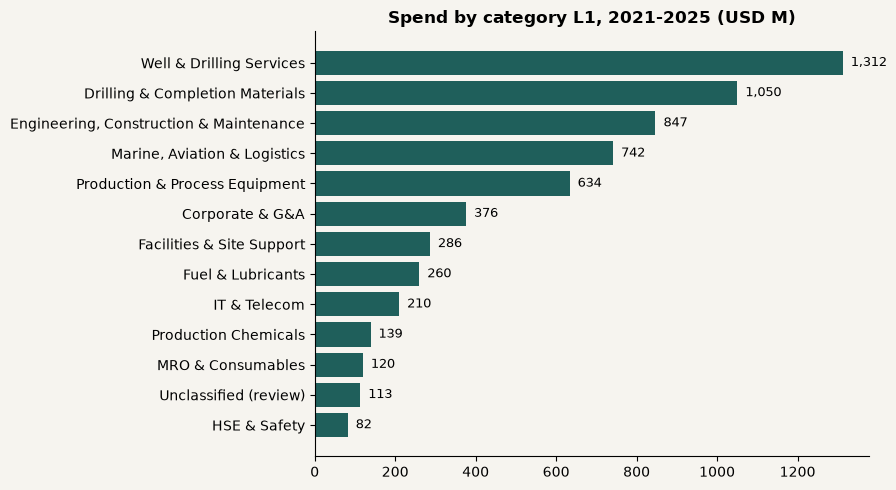

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
s = l1.spend.div(1e6).sort_values()
ax.barh(s.index, s.values, color=ACC)
for i, v in enumerate(s.values):
    ax.text(v, i, f"  {v:,.0f}", va="center", fontsize=9)
ax.set_title("Spend by category L1, 2021-2025 (USD M)"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "spend_by_l1.png", dpi=130); plt.show()

### 5.1 Pareto & tail spend

Active vendors: 1,311 | vendors making 80% of spend: 255 (19.5%)
Tail (last 5% of spend): 689 vendors, USD 309M, 57,436 POs


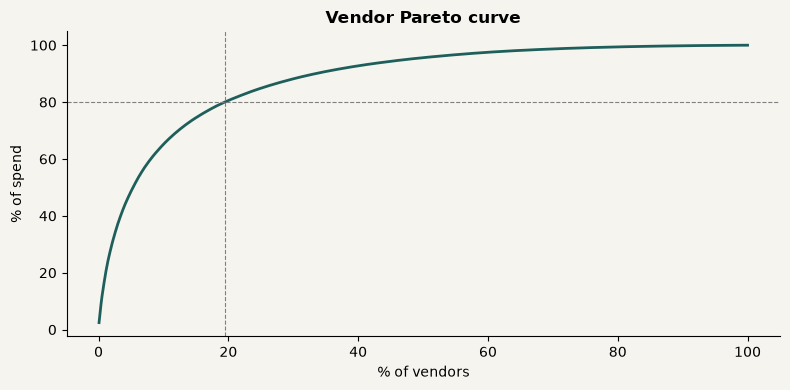

In [16]:
vs = df.groupby("master_vendor_id").net_value_usd.sum().sort_values(ascending=False)
cum = vs.cumsum() / vs.sum()
n80 = int((cum < 0.8).sum() + 1)
tail = vs[cum > 0.95]
print(f"Active vendors: {len(vs):,} | vendors making 80% of spend: {n80} ({n80/len(vs):.1%})")
print(f"Tail (last 5% of spend): {len(tail):,} vendors, USD {tail.sum()/1e6:,.0f}M, "
      f"{df[df.master_vendor_id.isin(tail.index)].po_number.nunique():,} POs")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100, color=ACC, lw=2)
ax.axhline(80, ls="--", c="grey", lw=.8); ax.axvline(n80 / len(vs) * 100, ls="--", c="grey", lw=.8)
ax.set_xlabel("% of vendors"); ax.set_ylabel("% of spend"); ax.set_title("Vendor Pareto curve")
plt.tight_layout(); plt.savefig(FIG / "pareto.png", dpi=130); plt.show()

### 5.2 Vendor fragmentation by category
How many vendors does each L3 category use, and how many would cover 80% of its spend?

In [17]:
def frag(g):
    s = g.groupby("master_vendor_id").net_value_usd.sum().sort_values(ascending=False)
    c = s.cumsum() / s.sum()
    return pd.Series({"spend_usd_m": s.sum() / 1e6, "vendors": len(s), "vendors_for_80pct": int((c < .8).sum() + 1),
                      "top1_share_%": s.iloc[0] / s.sum() * 100, "po_lines": len(g)})
fr = df[df.category_l3 != "Unclassified (review)"].groupby(["category_l1", "category_l3"]).apply(frag).reset_index()
fr["frag_ratio"] = fr.vendors / fr.vendors_for_80pct
fr.sort_values("vendors", ascending=False).head(12).round(1)

,category_l1,category_l3,spend_usd_m,vendors,vendors_for_80pct,top1_share_%,po_lines,frag_ratio
40,Production & Process Equipment,Pipe & Fittings,66.90,439.00,32.00,24.70,"73,887.00",13.70
39,Production & Process Equipment,Instrumentation,103.90,401.00,29.00,23.90,"42,662.00",13.80
42,Production & Process Equipment,Valves,130.50,368.00,27.00,23.80,"59,731.00",13.60
41,Production & Process Equipment,Pumps & Spares,162.30,366.00,27.00,26.80,"23,791.00",13.60
38,Production & Process Equipment,Electrical Equipment,65.90,364.00,29.00,24.00,"35,850.00",12.60
37,Production & Process Equipment,Compressor Spares,104.10,348.00,22.00,24.60,"15,813.00",15.80
30,MRO & Consumables,Gaskets & Seals,15.70,250.00,25.00,25.90,"43,139.00",10.00
31,MRO & Consumables,Tools & Hardware,22.30,245.00,27.00,26.60,"30,726.00",9.10
28,MRO & Consumables,Fasteners,11.10,232.00,19.00,24.80,"35,955.00",12.20
27,MRO & Consumables,Bearings & Power Transmission,49.30,224.00,25.00,24.00,"31,218.00",9.00


### 5.3 Contract coverage, local vs foreign, currency

In [18]:
df["on_contract"] = df.contract_no.notna()
cc = df.groupby("category_l1").apply(lambda g: pd.Series({
        "spend_usd_m": g.net_value_usd.sum() / 1e6,
        "contract_cov_%": g.loc[g.on_contract, "net_value_usd"].sum() / g.net_value_usd.sum() * 100,
        "local_vendor_%": g.loc[g.vendor_origin.str.startswith("Local"), "net_value_usd"].sum() / g.net_value_usd.sum() * 100,
        "usd_po_%": g.loc[g.currency.eq("USD"), "net_value_usd"].sum() / g.net_value_usd.sum() * 100})).sort_values("spend_usd_m", ascending=False)
print(f"Overall contract coverage: {df.loc[df.on_contract,'net_value_usd'].sum()/tot:.1%} | local vendor share: "
      f"{df.loc[df.vendor_origin.str.startswith('Local'),'net_value_usd'].sum()/tot:.1%}")
cc.round(1)

Overall contract coverage: 51.7% | local vendor share: 58.1%


,spend_usd_m,contract_cov_%,local_vendor_%,usd_po_%
category_l1,,,,
Well & Drilling Services,"1,312.40",76.00,36.30,75.90
Drilling & Completion Materials,"1,050.40",15.20,39.60,63.70
"Engineering, Construction & Maintenance",846.90,74.40,73.30,52.70
"Marine, Aviation & Logistics",741.60,75.20,67.70,57.50
Production & Process Equipment,633.50,14.90,43.30,60.00
Corporate & G&A,376.00,68.90,87.20,44.80
Facilities & Site Support,286.30,74.70,100.00,37.90
Fuel & Lubricants,259.90,14.30,99.30,13.90
IT & Telecom,209.80,65.30,55.20,62.90


### 5.4 Trend & seasonality

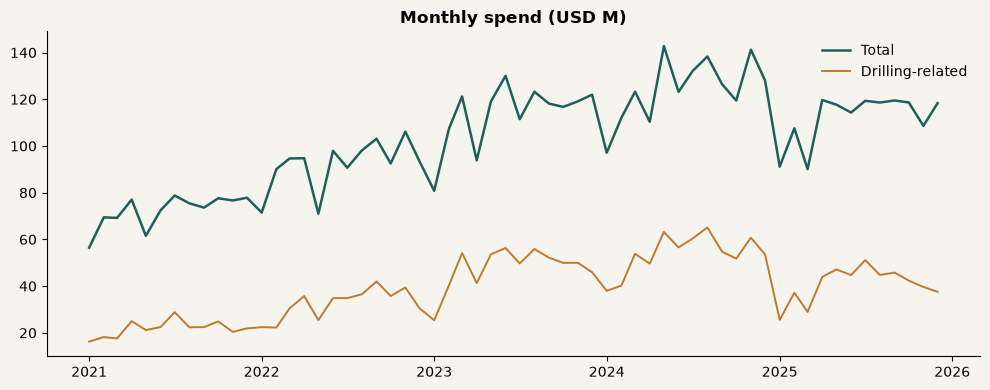

Indirect/MRO spend placed in Nov-Dec: 21.7% (2 of 12 months = 16.7%) -> year-end budget flush


In [19]:
m = df.set_index("po_date").resample("MS").net_value_usd.sum().div(1e6)
drill = df[df.category_l1.isin(["Drilling & Completion Materials", "Well & Drilling Services"])].set_index("po_date").resample("MS").net_value_usd.sum().div(1e6)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(m.index, m.values, color=ACC, lw=1.8, label="Total")
ax.plot(drill.index, drill.values, color="#c07a2c", lw=1.4, label="Drilling-related")
ax.set_title("Monthly spend (USD M)"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "monthly_trend.png", dpi=130); plt.show()
ga = df[df.category_l1.isin(["Corporate & G&A", "IT & Telecom", "MRO & Consumables", "HSE & Safety"])]
nd = ga[ga.po_date.dt.month.isin([11, 12])].net_value_usd.sum() / ga.net_value_usd.sum()
print(f"Indirect/MRO spend placed in Nov-Dec: {nd:.1%} (2 of 12 months = 16.7%) -> year-end budget flush")

### 5.5 Price dispersion on identical items
Same material code, same year, different vendors — how far apart are the unit prices (in USD)?

In [20]:
mat = df[df.material_code.notna() & df.unit_price.gt(0)].copy()
mat["unit_usd"] = mat.net_value_usd / mat.quantity
g = mat.groupby(["material_code", "year"]).agg(n=("unit_usd", "size"), vendors=("master_vendor_id", "nunique"),
                                              p25=("unit_usd", lambda x: x.quantile(.25)), med=("unit_usd", "median"))
g = g[(g.n >= 5) & (g.vendors >= 2)]
mat = mat.merge(g[["med", "p25"]], left_on=["material_code", "year"], right_index=True)
above = mat[mat.unit_usd > mat.p25]
saving = ((above.unit_usd - above.p25) * above.quantity).sum()
print(f"Material codes bought from 2+ vendors in the same year: {g.reset_index().material_code.nunique():,}")
print(f"Spend on those lines: USD {mat.net_value_usd.sum()/1e6:,.0f}M | gap to each item's P25 price: USD {saving/1e6:,.1f}M "
      f"({saving/mat.net_value_usd.sum():.1%})")

Material codes bought from 2+ vendors in the same year: 3,629
Spend on those lines: USD 1,294M | gap to each item's P25 price: USD 107.7M (8.3%)


## 6. Export for dashboard

In [21]:
def top(s, n): return s.sort_values(ascending=False).head(n)
by_year_l1 = df.pivot_table(index="year", columns="category_l1", values="net_value_usd", aggfunc="sum").div(1e6).round(2)
top_vendors = df.groupby(["master_vendor_name", "vendor_origin"]).agg(spend=("net_value_usd", "sum"), l3=("category_l3", lambda x: x.value_counts().index[0]),
                                                                    lines=("line_id", "size")).reset_index().sort_values("spend", ascending=False).head(15)
l3 = df.groupby(["category_l1", "category_l3"]).net_value_usd.sum().div(1e6).reset_index()
plant = df.groupby("plant").net_value_usd.sum().div(1e6)
monthly = m.round(2)
dash = {
  "kpi": {"spend_b": round(tot / 1e9, 2), "lines": int(len(df)), "pos": int(df.po_number.nunique()), "vendors": int(len(vs)),
          "vendor_ids_raw": int(len(vendors)), "cov_before": round(cov_before * 100, 1), "cov_after": round(cov_after * 100, 1),
          "spend_cov_after": round((1 - review.net_value_usd.sum() / tot) * 100, 1), "qa_acc": round(final_acc * 100, 1),
          "buyer_acc": round(manual_acc * 100, 1), "relabel_lines": int(relabel.sum()), "relabel_usd_m": round(df[relabel].net_value_usd.sum() / 1e6, 1),
          "review_lines": int(len(review)), "n80": n80, "tail_vendors": int(len(tail)), "tail_usd_m": round(tail.sum() / 1e6, 1),
          "contract_cov": round(df.loc[df.on_contract, "net_value_usd"].sum() / tot * 100, 1),
          "local_share": round(df.loc[df.vendor_origin.str.startswith("Local"), "net_value_usd"].sum() / tot * 100, 1),
          "price_gap_usd_m": round(saving / 1e6, 1), "dup_vendor_records": int(len(dup) - dup.tax_id.nunique()),
          "dup_spend_usd_m": round(spend_on_dups / 1e6, 1), "yearend_share": round(nd * 100, 1)},
  "years": [int(y) for y in by_year_l1.index], "by_year_l1": {c: by_year_l1[c].fillna(0).tolist() for c in by_year_l1.columns},
  "l1": [{"name": k, "spend": round(v.spend / 1e6, 1), "lines": int(v.lines), "vendors": int(v.vendors)} for k, v in l1.iterrows()],
  "l3": [{"l1": r.category_l1, "l3": r.category_l3, "spend": round(r.net_value_usd, 1)} for r in l3.itertuples()],
  "frag": fr.sort_values("vendors", ascending=False).head(15).round(1).to_dict("records"),
  "top_vendors": [{"name": r.master_vendor_name, "origin": r.vendor_origin, "spend": round(r.spend / 1e6, 1), "l3": r.l3, "lines": int(r.lines)} for r in top_vendors.itertuples()],
  "plant": {k: round(v, 1) for k, v in plant.items()},
  "monthly": {"labels": [d.strftime("%Y-%m") for d in monthly.index], "total": monthly.tolist(), "drilling": drill.round(2).tolist()},
  "contract": cc.round(1).reset_index().to_dict("records"),
  "pareto": {"x": [round(x, 2) for x in (np.arange(1, len(cum) + 1) / len(cum) * 100)[::5]], "y": [round(y * 100, 2) for y in cum.values[::5]]},
}
Path("../docs").mkdir(exist_ok=True)
(Path("../docs") / "dashboard_data.json").write_text(json.dumps(dash))
df[["line_id", "po_number", "po_line", "po_date", "plant", "master_vendor_id", "master_vendor_name", "item_description", "net_value_usd",
    "category_l1", "category_l2", "category_l3", "class_source", "confidence"]].to_parquet(OUT / "po_lines_classified.parquet", index=False)
review.sort_values("net_value_usd", ascending=False)[["line_id", "po_number", "item_description", "net_value_usd", "pred_l3", "confidence"]] \
      .to_csv(OUT / "manual_review_queue.csv", index=False)
print(json.dumps(dash["kpi"], indent=1))

{
 "spend_b": 6.17,
 "lines": 851005,
 "pos": 321867,
 "vendors": 1311,
 "vendor_ids_raw": 1383,
 "cov_before": 46.9,
 "cov_after": 92.8,
 "spend_cov_after": 98.2,
 "qa_acc": 99.5,
 "buyer_acc": 90.6,
 "relabel_lines": 6874,
 "relabel_usd_m": 77.0,
 "review_lines": 61415,
 "n80": 255,
 "tail_vendors": 689,
 "tail_usd_m": 308.6,
 "contract_cov": 51.7,
 "local_share": 58.1,
 "price_gap_usd_m": 107.7,
 "dup_vendor_records": 72,
 "dup_spend_usd_m": 97.3,
 "yearend_share": 21.7
}


In [22]:
from IPython.display import Markdown
k = dash["kpi"]
mat_cov = cc.loc[["Production & Process Equipment", "MRO & Consumables", "Drilling & Completion Materials", "Production Chemicals"], "contract_cov_%"]
srv_cov = cc.loc[["Well & Drilling Services", "Marine, Aviation & Logistics", "Engineering, Construction & Maintenance"], "contract_cov_%"].mean()
fv = fr[fr.category_l1.isin(["Production & Process Equipment", "MRO & Consumables"])]
Markdown(f"""## 7. Findings & recommendations

| # | Finding | Recommendation |
|---|---------|----------------|
| 1 | Category coverage rose from **{k['cov_before']}% to {k['cov_after']}% of PO lines ({k['spend_cov_after']}% of spend)**. On the validated sample, auto-assigned categories are **{k['qa_acc']}%** correct vs **{k['buyer_acc']}%** for buyer labels. | Suggest the category at PR creation; buyers confirm instead of typing. |
| 2 | **{k['relabel_lines']:,} buyer labels (USD {k['relabel_usd_m']}M)** contradict a high-confidence prediction and were corrected; **{k['review_lines']:,} lines** have vague descriptions ("sesuai penawaran", "lihat lampiran") and sit in the review queue. | Make the item description a structured, required field; block "as per attachment" descriptions above a value threshold. |
| 3 | **{k['dup_vendor_records']} duplicate vendor records** (same tax ID) held **USD {k['dup_spend_usd_m']}M** that vendor-level reports split in two. | Merge the records; block vendor creation when the tax ID already exists. |
| 4 | **{k['n80']} of {k['vendors']:,} vendors cover 80% of spend**; the last 5% of spend is spread over **{k['tail_vendors']} vendors** (USD {k['tail_usd_m']}M). | Move tail MRO/indirect buying to catalogues and a short distributor panel. |
| 5 | Process-equipment and MRO categories use **{int(fv.vendors.min())}–{int(fv.vendors.max())} vendors** each while **{int(fv.vendors_for_80pct.min())}–{int(fv.vendors_for_80pct.max())}** cover 80% of their spend. Material categories are **{mat_cov.min():.0f}–{mat_cov.max():.0f}%** on contract vs ~{srv_cov:.0f}% for major services. | Framework agreements for valves, pipe & fittings, instrumentation, pumps and MRO consumables. |
| 6 | On identical material codes bought from 2+ vendors in the same year, prices above each item's P25 add up to **USD {k['price_gap_usd_m']}M** (upper bound). | Price harmonisation in the framework tenders; realistic capture of 20–30% is **USD {k['price_gap_usd_m']*0.2:.0f}–{k['price_gap_usd_m']*0.3:.0f}M over 5 years**. |
| 7 | **{k['yearend_share']}%** of indirect/MRO spend lands in Nov–Dec (16.7% if spread evenly). | Quarterly budget release and a PR cut-off date for non-critical indirect items. |
| 8 | Spend grew from **USD {yr[2021]:,.0f}M (2021) to USD {yr.max():,.0f}M ({yr.idxmax()})** with the drilling campaign. | Plan OCTG, bits and rig services against the drilling schedule 12 months ahead. |
""")

## 7. Findings & recommendations

| # | Finding | Recommendation |
|---|---------|----------------|
| 1 | Category coverage rose from **46.9% to 92.8% of PO lines (98.2% of spend)**. On the validated sample, auto-assigned categories are **99.5%** correct vs **90.6%** for buyer labels. | Suggest the category at PR creation; buyers confirm instead of typing. |
| 2 | **6,874 buyer labels (USD 77.0M)** contradict a high-confidence prediction and were corrected; **61,415 lines** have vague descriptions ("sesuai penawaran", "lihat lampiran") and sit in the review queue. | Make the item description a structured, required field; block "as per attachment" descriptions above a value threshold. |
| 3 | **72 duplicate vendor records** (same tax ID) held **USD 97.3M** that vendor-level reports split in two. | Merge the records; block vendor creation when the tax ID already exists. |
| 4 | **255 of 1,311 vendors cover 80% of spend**; the last 5% of spend is spread over **689 vendors** (USD 308.6M). | Move tail MRO/indirect buying to catalogues and a short distributor panel. |
| 5 | Process-equipment and MRO categories use **220–439 vendors** each while **19–32** cover 80% of their spend. Material categories are **15–16%** on contract vs ~75% for major services. | Framework agreements for valves, pipe & fittings, instrumentation, pumps and MRO consumables. |
| 6 | On identical material codes bought from 2+ vendors in the same year, prices above each item's P25 add up to **USD 107.7M** (upper bound). | Price harmonisation in the framework tenders; realistic capture of 20–30% is **USD 22–32M over 5 years**. |
| 7 | **21.7%** of indirect/MRO spend lands in Nov–Dec (16.7% if spread evenly). | Quarterly budget release and a PR cut-off date for non-critical indirect items. |
| 8 | Spend grew from **USD 866M (2021) to USD 1,494M (2024)** with the drilling campaign. | Plan OCTG, bits and rig services against the drilling schedule 12 months ahead. |
